# Bottom age tracer in ACCESS-OM3

The age tracer is set every time step to zero at the surface. Young bottom age tracer values indicate recent contact with the surface, allowing us to use it as a proxy for deep convection, Dense Shelf Water and Antarctic Bottom Water formation, and their pathways.

Many global models struggle to simulate Antarctic Bottom Water formation through Dense Shelf Water export down the continental slope, where it mixes with surrounding waters; instead, they often form it in the open ocean through deep convection.

The bottom age tracer helps investigate how models form Antarctic Bottom Water. Since Dense Shelf Water export is sensitive to stratification, a model's ability to simulate these processes may change during the run. Therefore, we recommend examining the bottom age tracer early in the simulation (e.g., around year 10) and towards the end. The year can be selected in the cell following `Select year to plot`.

In [1]:
#parameters

# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-03-06-2026/cm3-datastore/cm3-datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-03-06-2026/"
nbname = "Bottom_age_tracer_in_ACCESS_OM3.ipynb"


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
from exptdata_access import get_exptname_from_path
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
from exptdata_access import guess_experiment_from_esm_file
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]  # OM3 or CM3

In [4]:
import os
plotfolder = str(cwd) + "/" if cwd else "./"
os.makedirs(plotfolder, exist_ok=True)
notebook_name="Bottom_age_tracer_in_ACCESS_OM3"

In [5]:
import intake
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean as cm
from distributed import Client

# Stop annoying warnings coming out of xarray.
import warnings
warnings.filterwarnings('ignore')

fig_path = plotfolder

In [6]:
client = Client(threads_per_worker=1) 
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
print(client.dashboard_link)

http://127.0.0.1:8787/status


Open intake datastore:

In [7]:
datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

## Select year to plot

In [8]:
# Define year to open, chose one of the examples or change manually.
# OM3 uses this year if the run has it, otherwise the run's last complete year
# (e.g. the 8km RYF run starts in 1900, so it uses 1909 = model year 10). OM2-01 always uses this year.
#
# ACCESS-CM3: the age tracer is initialised to zero at the start of the run, so in an
# early year every bottom cell has aged by the same ~1 year and dividing by the maximum
# flattens the whole map to ~1. Use the run's last complete year instead, and age the
# cj877 reference by the same elapsed time (derived in the cells below, not hardcoded).
year = None if model_name == "ACCESS-CM3" else 1970  # None = use the run's last complete year
# year = 2020  # Assumes IAF simulation, later in the run
dates = f'{year}.*' if year is not None else None  # only used for the OM2-01 reference

User should not need to adjust anything in code below.

## Load OM3 bottom age tracer

In [9]:
from model_agnostic import years_window, year_slice

age_search = datastore.search(variable="agessc", frequency="1mon")
if year is not None and any(str(d).startswith(str(year)) for d in age_search.df.start_date):
    year_OM3 = year
else:
    # last complete year: the year before the last file's end date
    year_OM3 = int(max(str(d) for d in age_search.df.end_date)[:4]) - 1
    if year is not None:
        print(f"Year {year} not in this run; using its last complete year {year_OM3}")

# Elapsed time since the age tracer was initialised to zero, so the reference run can be
# aged to match: two age tracers are only comparable at the same tracer age.
first_year_OM3 = int(min(str(d) for d in age_search.df.start_date)[:4])
nyears_OM3 = year_OM3 - first_year_OM3 + 1
print(f"Age tracer: {first_year_OM3}-{year_OM3}, i.e. {nyears_OM3} years since the run started")

# files can straddle year boundaries, so also open those starting the year before, then keep year_OM3 only
age_OM3 = age_search.search(start_date=f"(?:{year_OM3 - 1}|{year_OM3}).*").to_dask(
    xarray_open_kwargs = dict(
        # One chunk per month. Without "time", a chunk is a whole year-file (75 levels
        # x 1152 x 1440 x 12 months = 6 GB), and when the search spans two year-files
        # dask has to hold both to concatenate them, which kills the workers. Chunking
        # on time keeps each chunk ~0.5 GB and suits the .mean("time") below.
        chunks={"time": 1, "yh": -1, "xh": -1},
        decode_timedelta=True
    )
)
age_OM3 = age_OM3.sel(time=year_slice(years_window(age_OM3.time, period=(year_OM3, year_OM3))))

Age tracer: 1981-2030, i.e. 50 years since the run started


In [10]:
age_OM3

<xarray.Dataset> Size: 6GB
Dimensions:     (time: 12, z_l: 75, yh: 1152, xh: 1440, nv: 2, z_i: 76)
Coordinates:
  * time        (time) datetime64[ns] 96B 2030-01-16T12:00:00 ... 2030-12-16T...
  * z_l         (z_l) float64 600B 0.5413 1.681 2.94 ... 5.511e+03 5.709e+03
  * yh          (yh) float64 9kB -81.58 -81.52 -81.45 ... 89.74 89.84 89.95
  * xh          (xh) float64 12kB -279.9 -279.6 -279.4 ... 79.38 79.62 79.88
  * nv          (nv) float64 16B 1.0 2.0
  * z_i         (z_i) float64 608B 0.0 1.083 2.279 ... 5.61e+03 5.809e+03
Data variables:
    agessc      (time, z_l, yh, xh) float32 6GB dask.array<chunksize=(1, 75, 1152, 1440), meta=np.ndarray>
    average_T1  (time) datetime64[ns] 96B dask.array<chunksize=(1,), meta=np.ndarray>
    average_T2  (time) datetime64[ns] 96B dask.array<chunksize=(1,), meta=np.ndarray>
    average_DT  (time) timedelta64[ns] 96B dask.array<chunksize=(1,), meta=np.ndarray>
    time_bnds   (time, nv) datetime64[ns] 192B dask.array<chunksize=(1, 2), meta=np.ndarray>
Attributes: (12/17)
    NumFilesInSet:                            1
    title:                                    ACCESS-CM3
    associated_files:                         areacello: access-cm3.mom6.stat...
    grid_type:                                regular
    grid_tile:                                N/A
    intake_esm_vars:                          ('agessc', 'average_DT', 'avera...
    ...                                       ...
    intake_esm_attrs:variable_cell_methods:   area:mean z_l:mean yh:mean xh:m...
    intake_esm_attrs:variable_units:          yr,days,days since 1900-01-01,d...
    intake_esm_attrs:realm:                   ocean
    intake_esm_attrs:temporal_label:          mean
    intake_esm_attrs:_data_format_:           netcdf
    intake_esm_dataset_key:                   ocean.1mon.nv:2.xh:1440.yh:1152...

In [11]:
# Refine area and take annual mean
age_OM3 = age_OM3.agessc.sel(yh=slice(-90,-50)).mean('time').load() 

# Get bottom tracer
depth_array_OM3 = age_OM3 * 0 + age_OM3.z_l
max_depth_OM3   = depth_array_OM3.max(dim='z_l', skipna=True)

age_bot_OM3 = age_OM3.where(depth_array_OM3.z_l >= max_depth_OM3)
age_bot_OM3 = age_bot_OM3.sum(dim='z_l').load()

# Finally, normalise age tracer by the max value
age_bot_normalised_OM3 = age_bot_OM3/age_bot_OM3.max()

#### Mask contiental shelf

Instructions for how to extract the shelf mask for the 1000 m isobath in OM3 can be found in the COSIMA recipes under [Create_contour.ipynb](https://github.com/COSIMA/cosima-recipes/blob/main/03-Advanced-Recipes/Create_contour.ipynb).

In [12]:
# Load shelf mask (1000 m isobath on the matching OM3 grid)
path_OM3_1000m = {
    '25km': '/g/data/ol01/outputs/access-om3-25km/Antarctic_slope_contours/Antarctic_slope_contour_1000m_OM3_25km.nc',
    '100km': '/g/data/ol01/outputs/access-om3-100km/Antarctic_slope_contours/Antarctic_slope_contour_1000m_OM3_100km.nc',
    '8km': '/g/data/ol01/outputs/access-om3-8km/Antarctic_slope_contours/Antarctic_slope_contour_1000m_OM3_8km.nc',
}
om3_res = {360: '100km', 1440: '25km', 4320: '8km'}[age_OM3.sizes['xh']]

contour_masked_above_OM3 = xr.open_mfdataset(path_OM3_1000m[om3_res]).contour_masked_above

shelf_mask_OM3 = contour_masked_above_OM3.where(contour_masked_above_OM3==0, 1)
shelf_mask_OM3 = shelf_mask_OM3.where(shelf_mask_OM3==1)

In [13]:
# Mask the data
age_bot_masked_OM3 = age_bot_normalised_OM3*shelf_mask_OM3

## Compare to age tracer from OM2-01

Note there is no age tracer saved for OM2-025 (only for the first three years and then from 2300 onwards). OM2-01 has good DSW overflow and AABW formation so it makes sense to compare to this configuration.

In [14]:
if model_name == "ACCESS-CM3":
    # ACCESS-CM2 cj877 control archive, as used by the other CM3-capable
    # notebooks. cj877's age_global shares MOM5 dims/naming with OM2-01's.
    from pathlib import Path
    cm2_dir = Path("/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn")
    data_name = "ACCESS-CM2"
    ref_label = "cj877"
else:
    catalog  = intake.cat.access_nri
    expt_01 = '01deg_jra55v140_iaf' # cylce 1 of OM2-01 IAF simulation
    # expt_01  = '01deg_jra55v13_ryf9091' # use for RYF comparison
    # expt_025 = '025deg_jra55_ryf9091_gadi'
    data_name = "ACCESS-OM2-01"
    ref_label = expt_01


In [15]:
if model_name == "ACCESS-CM3":
    # cj877 aged for the same elapsed time as the CM3 run (derived above, not hardcoded).
    # Both tracers start at zero, so they are only comparable at the same tracer age.
    cj877_year = nyears_OM3
    files = sorted(cm2_dir.glob(f"ocean-3d-age_global-1-monthly-mean-ym_{cj877_year:04d}_*.nc"))
    if not files:
        raise FileNotFoundError(f"No cj877 age_global files found for model year {cj877_year}")
    age_OM2_01 = xr.open_mfdataset(
        files, combine="by_coords", parallel=True,
        chunks={"time": 1, "yt_ocean": -1, "xt_ocean": -1, "st_ocean": -1},
        decode_timedelta=True,
        use_cftime=True,  # cj877 model years can't be datetime64
        data_vars="minimal", coords="minimal", compat="override",
    )
else:
    age_OM2_01 = catalog[expt_01].search(variable="age_global", frequency="1mon", start_date=dates).to_dask(
        xarray_open_kwargs = dict(
            chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
            # chunks={"time": -1}, # Good for temporal operations, but not spatial
            decode_timedelta=True
        )
    )


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x149452685610>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f918481ee0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f911beb3b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14f911beb710>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x149450806f60>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x149450805fd0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


... (6 outputs left out)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x149450c698e0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14944b6053a0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:767: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  return self.func(*new_argspec, **kwargs)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:767: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  return self.func(*new_argspec, **kwargs)


In [16]:
# Refine area and take annual mean
age_OM2_01 = age_OM2_01.age_global.sel(yt_ocean=slice(-90,-50)).mean('time').load() 

# Get bottom tracer
depth_array_OM2_01 = age_OM2_01 * 0 + age_OM2_01.st_ocean
max_depth_OM2_01   = depth_array_OM2_01.max(dim='st_ocean', skipna=True)

age_bot_OM2_01 = age_OM2_01.where(depth_array_OM2_01.st_ocean >= max_depth_OM2_01)
age_bot_OM2_01 = age_bot_OM2_01.sum(dim='st_ocean').load()

# Finally, normalise age tracer by the max value
age_bot_normalised_OM2_01 = age_bot_OM2_01/age_bot_OM2_01.max()

#### Mask continental shelf

The file for the OM2-01 grid is saved as a *.npz file. Let's convert it to a dataarray for easier handling.

In [17]:
if model_name == "ACCESS-CM3":
    # 1000 m slope contour on cj877's own grid (ACCESS-OM2-025 B-grid), built
    # with the COSIMA cosima-recipes Create_contour.ipynb 'Approach 1' method.
    path_OM2_01_1000m = '/g/data/ik11/grids/Antarctic_slope_contour_1000m_cj877_025deg.npz'
else:
    path_OM2_01_1000m = '/g/data/ik11/grids/Antarctic_slope_contour_1000m.npz'  # original /g/data/g40/akm157/... path no longer exists; identical file lives here

contour_data_OM2_01  = np.load(path_OM2_01_1000m)

# Extract relevant information and write as dataarray
contour_masked_above_OM2_01 = xr.DataArray(
    contour_data_OM2_01['contour_masked_above'],
    dims=("yt_ocean", "xt_ocean"),
    coords={
        "xt_ocean": contour_data_OM2_01['xt_ocean'],
        "yt_ocean": contour_data_OM2_01['yt_ocean'],
    }
)

shelf_mask_OM2_01 = contour_masked_above_OM2_01.where(contour_masked_above_OM2_01==0, 1)
shelf_mask_OM2_01 = shelf_mask_OM2_01.where(shelf_mask_OM2_01==1)

In [18]:
# Mask the data
age_bot_masked_OM2_01 = age_bot_normalised_OM2_01*shelf_mask_OM2_01

## Plotting

In [19]:
# Land mask
var_search = datastore.search(variable="deptho")
ds = var_search.search(path=var_search.df.path[0]).to_dask() # we only need one file as bathymetry doesn't change
bathymetry = ds["deptho"].load()
land = xr.where(np.isnan(bathymetry.rename("land")), 1, np.nan)
land = land.sel(yh=slice(-90,-50))

ft_size = 12 # fontsize

In [20]:
# 1000 m contour
slope_contour = contour_masked_above_OM3.where(contour_masked_above_OM3>0)
slope_contour = slope_contour/slope_contour

Plot MC_25km_jra_iaf-1.0-beta-5165c0f8 and 01deg_jra55v140_iaf (year 2014)

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-03-06-2026/mkmd/Bottom_age_tracer_in_ACCESS_OM3_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-03-06-2026/mkmd/Bottom_age_tracer_in_ACCESS_OM3.md
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-03-06-2026/mkmd/Bottom_age_tracer_in_ACCESS_OM3.md successfully.


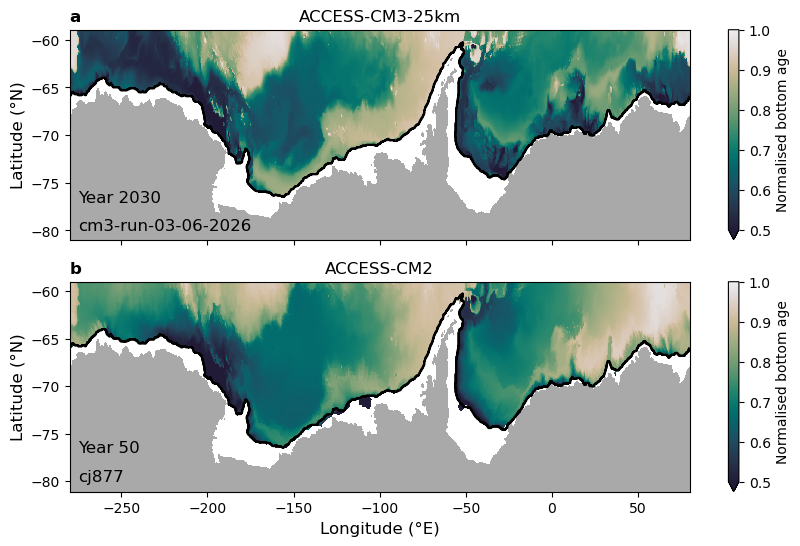

In [21]:
plt.figure(figsize=(10, 6))

plt.subplot(211)
land.plot.contourf(colors="darkgrey", add_colorbar=False)
age_bot_masked_OM3.plot(cmap=cm.cm.rain_r, vmin=0.5, vmax=1, cbar_kwargs={'label': "Normalised bottom age"})
slope_contour.fillna(2).plot.contour(levels=[0,1], colors='black', linewidths=1.5)
plt.title(f'{model_name}-{om3_res}'), plt.title('a', fontweight='bold', fontsize=ft_size, loc='left')
plt.tick_params(labelbottom=False)
plt.xlabel(''), plt.ylabel('Latitude (°N)', fontsize=ft_size)
plt.text(-275, -77, f'Year {year_OM3}', fontsize=ft_size)
plt.text(-275, -80, get_exptname_from_path(esm_file), fontsize=ft_size)

plt.subplot(212)
land.plot.contourf(colors="darkgrey", add_colorbar=False)
age_bot_masked_OM2_01.plot(cmap=cm.cm.rain_r, vmin=0.5, vmax=1, cbar_kwargs={'label': "Normalised bottom age"})
slope_contour.fillna(2).plot.contour(levels=[0,1], colors='black', linewidths=1.5)
plt.title(f'{data_name}'), plt.title('b', fontweight='bold', fontsize=ft_size, loc='left')
plt.xlabel('Longitude (°E)', fontsize=ft_size), plt.ylabel('Latitude (°N)', fontsize=ft_size)
ref_year = cj877_year if model_name == "ACCESS-CM3" else year  # cj877 model year, or OM2-01's calendar year
plt.text(-275, -77, f'Year {ref_year}', fontsize=ft_size)
plt.text(-275, -80, ref_label, fontsize=ft_size)

mkmd.savefig(plt.gcf(),"Bottom age tracer", f"Normalised bottom age comparing {model_name} (year {year_OM3}) and {data_name} (year {ref_year})" , dpi=150)